In [8]:
!pip install -q tensorflow numpy matplotlib scikit-learn pillow

In [5]:
import tensorflow as tf

print("TensorFlow:", tf.__version__)

try:
    import tensorflow_datasets as tfds
    print("TensorFlow Datasets: installed")

    print("Available GTSRB datasets:")
    print([
        name for name in tfds.list_builders()
        if "gtsrb" in name.lower()
    ])

except Exception as e:
    print("Dataset library error:", e)

TensorFlow: 2.21.0
TensorFlow Datasets: installed
Available GTSRB datasets:
[]


In [6]:
!pip -q install kagglehub

import kagglehub

try:
    path = kagglehub.dataset_download(
        "meowmeowmeowmeowmeow/gtsrb-german-traffic-sign"
    )
    print("Dataset downloaded to:", path)
except Exception as e:
    print("Download error:", str(e))

100%|██████████| 612M/612M [00:03<00:00, 161MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign/versions/1


In [7]:
import os

DATASET_PATH = "/root/.cache/kagglehub/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign/versions/1"

for root, dirs, files in os.walk(DATASET_PATH):
    level = root.replace(DATASET_PATH, "").count(os.sep)
    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")
        if level == 2:
            dirs[:] = []

1/
  meta/
  test/
  train/
    23/
    38/
    36/
    4/
    3/
    12/
    26/
    41/
    2/
    10/
    0/
    15/
    40/
    9/
    39/
    7/
    19/
    22/
    29/
    35/
    42/
    17/
    11/
    16/
    25/
    37/
    33/
    31/
    13/
    14/
    27/
    6/
    20/
    24/
    18/
    32/
    30/
    1/
    28/
    21/
    8/
    34/
    5/
  Test/
  Meta/
  Train/
    23/
    38/
    36/
    4/
    3/
    12/
    26/
    41/
    2/
    10/
    0/
    15/
    40/
    9/
    39/
    7/
    19/
    22/
    29/
    35/
    42/
    17/
    11/
    16/
    25/
    37/
    33/
    31/
    13/
    14/
    27/
    6/
    20/
    24/
    18/
    32/
    30/
    1/
    28/
    21/
    8/
    34/
    5/


In [8]:
import os
import numpy as np
import tensorflow as tf
from PIL import Image

DATASET_PATH = "/root/.cache/kagglehub/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign/versions/1"
TRAIN_PATH = os.path.join(DATASET_PATH, "Train")

X = []
y = []

for class_id in range(43):
    folder = os.path.join(TRAIN_PATH, str(class_id))

    for filename in os.listdir(folder):
        if filename.lower().endswith((".png", ".jpg", ".jpeg", ".ppm")):
            image_path = os.path.join(folder, filename)

            try:
                img = Image.open(image_path).convert("RGB")
                img = img.resize((32, 32))
                X.append(np.array(img))
                y.append(class_id)
            except Exception:
                pass

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.int64)

print("Images loaded:", len(X))
print("Image shape:", X.shape)
print("Classes:", len(np.unique(y)))

Images loaded: 39209
Image shape: (39209, 32, 32, 3)
Classes: 43


In [9]:
from sklearn.model_selection import train_test_split

# Normalize images to the range 0–1
X = X / 255.0

# Split: 80% training, 20% validation
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Number of classes:", len(np.unique(y)))

Training images: 31367
Validation images: 7842
Number of classes: 43


In [10]:
import tensorflow as tf
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(43, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 361,067 (1.38 MB)

 Trainable params: 361,067 (1.38 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=5,
    batch_size=64,
    verbose=1
)

Epoch 1/5
491/491 ━━━━━━━━━━━━━━━━━━━━ 75s 150ms/step - accuracy: 0.3372 - loss: 2.2795 - val_accuracy: 0.6891 - val_loss: 1.0317
Epoch 2/5
491/491 ━━━━━━━━━━━━━━━━━━━━ 78s 143ms/step - accuracy: 0.7151 - loss: 0.8524 - val_accuracy: 0.9332 - val_loss: 0.2850
Epoch 3/5
491/491 ━━━━━━━━━━━━━━━━━━━━ 81s 141ms/step - accuracy: 0.8701 - loss: 0.4017 - val_accuracy: 0.9676 - val_loss: 0.1279
Epoch 4/5
491/491 ━━━━━━━━━━━━━━━━━━━━ 75s 152ms/step - accuracy: 0.9173 - loss: 0.2540 - val_accuracy: 0.9834 - val_loss: 0.0719
Epoch 5/5
491/491 ━━━━━━━━━━━━━━━━━━━━ 70s 143ms/step - accuracy: 0.9431 - loss: 0.1728 - val_accuracy: 0.9902 - val_loss: 0.0433


In [12]:
# Evaluate the trained model
val_loss, val_accuracy = model.evaluate(
    X_val, y_val, verbose=1
)

print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")
print(f"Validation Loss: {val_loss:.4f}")

246/246 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - accuracy: 0.9902 - loss: 0.0433
Validation Accuracy: 99.02%
Validation Loss: 0.0433


In [14]:
import os

os.makedirs("/content/traffic_sign_model", exist_ok=True)

model.save("/content/traffic_sign_model/traffic_sign_cnn.keras")

print("Model saved successfully!")

Model saved successfully!


In [15]:
val_loss, val_accuracy = model.evaluate(X_val, y_val, verbose=1)

print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")
print(f"Validation Loss: {val_loss:.4f}")

246/246 ━━━━━━━━━━━━━━━━━━━━ 7s 28ms/step - accuracy: 0.9902 - loss: 0.0433
Validation Accuracy: 99.02%
Validation Loss: 0.0433


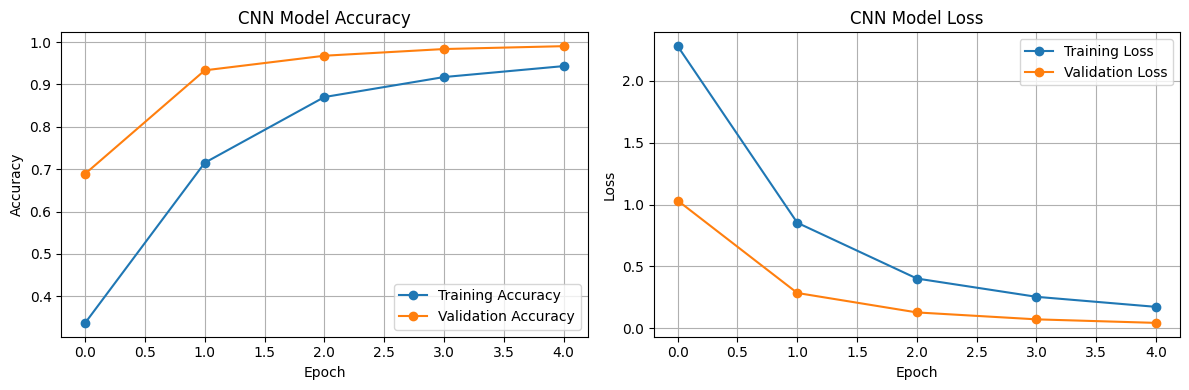

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], marker="o", label="Training Accuracy")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation Accuracy")
plt.title("CNN Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], marker="o", label="Training Loss")
plt.plot(history.history["val_loss"], marker="o", label="Validation Loss")
plt.title("CNN Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

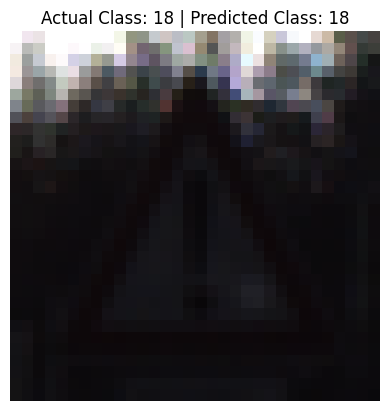

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import random

idx = random.randrange(len(X_val))
img = X_val[idx]

prediction = model.predict(img[None, ...], verbose=0)
predicted_class = np.argmax(prediction)

plt.imshow(img)
plt.title(
    f"Actual Class: {y_val[idx]} | Predicted Class: {predicted_class}"
)
plt.axis("off")
plt.show()

In [19]:
from google.colab import drive
drive.mount('/content/drive')

model.save('/content/drive/MyDrive/traffic_sign_cnn.keras')

print("Model saved to Google Drive!")

Mounted at /content/drive
Model saved to Google Drive!


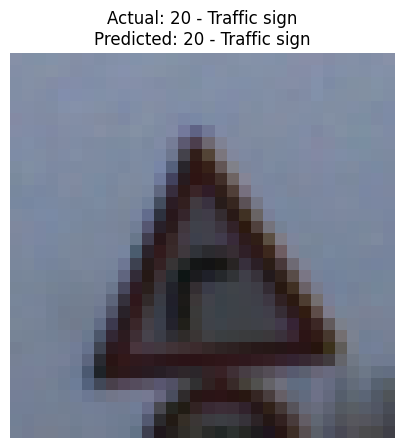

In [20]:
class_names = {
    18: "General caution"
}

idx = random.randrange(len(X_val))
img = X_val[idx]

prediction = model.predict(img[None, ...], verbose=0)
predicted_class = int(np.argmax(prediction))
actual_class = int(y_val[idx])

plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.title(
    f"Actual: {actual_class} - {class_names.get(actual_class, 'Traffic sign')}\n"
    f"Predicted: {predicted_class} - {class_names.get(predicted_class, 'Traffic sign')}"
)
plt.axis("off")
plt.show()

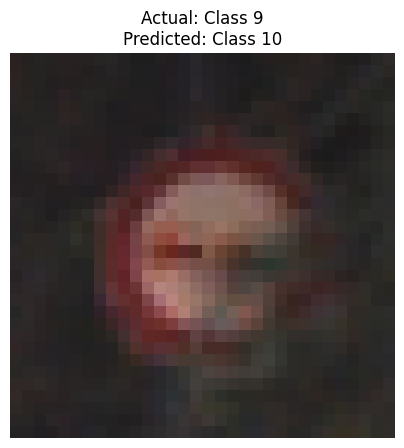

In [21]:
class_names = {
    18: "General caution",
    20: "Dangerous curves ahead"
}

idx = random.randrange(len(X_val))
img = X_val[idx]

prediction = model.predict(img[None, ...], verbose=0)
predicted_class = int(np.argmax(prediction))
actual_class = int(y_val[idx])

plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.title(
    f"Actual: {class_names.get(actual_class, 'Class ' + str(actual_class))}\n"
    f"Predicted: {class_names.get(predicted_class, 'Class ' + str(predicted_class))}"
)
plt.axis("off")
plt.show()

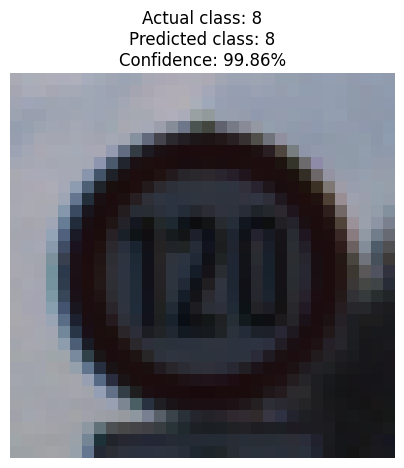

In [22]:
import numpy as np
import matplotlib.pyplot as plt

idx = random.randrange(len(X_val))
img = X_val[idx]

probabilities = model.predict(img[None, ...], verbose=0)[0]
predicted_class = int(np.argmax(probabilities))
actual_class = int(y_val[idx])

plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.title(
    f"Actual class: {actual_class}\n"
    f"Predicted class: {predicted_class}\n"
    f"Confidence: {probabilities[predicted_class] * 100:.2f}%"
)
plt.axis("off")
plt.show()

In [23]:
from sklearn.metrics import classification_report, accuracy_score
import numpy as np

y_pred = np.argmax(model.predict(X_val, verbose=0), axis=1)

print("Final Validation Accuracy:",
      f"{accuracy_score(y_val, y_pred) * 100:.2f}%")

print("\nClassification Report:\n")
print(classification_report(y_val, y_pred, zero_division=0))

Final Validation Accuracy: 99.02%

Classification Report:

              precision    recall  f1-score   support

           0       1.00      0.86      0.92        42
           1       0.99      0.97      0.98       444
           2       0.97      0.99      0.98       450
           3       0.98      0.99      0.98       282
           4       0.99      0.99      0.99       396
           5       0.97      0.96      0.96       372
           6       1.00      0.99      0.99        84
           7       0.98      0.99      0.99       288
           8       0.98      1.00      0.99       282
           9       1.00      0.99      0.99       294
          10       1.00      1.00      1.00       402
          11       0.98      1.00      0.99       264
          12       1.00      1.00      1.00       420
          13       0.99      1.00      1.00       432
          14       1.00      1.00      1.00       156
          15       1.00      0.99      1.00       126
          16       1.0

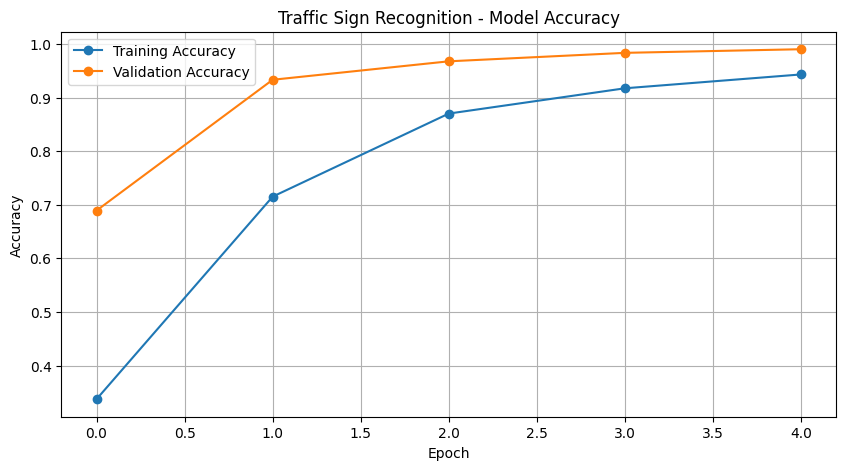

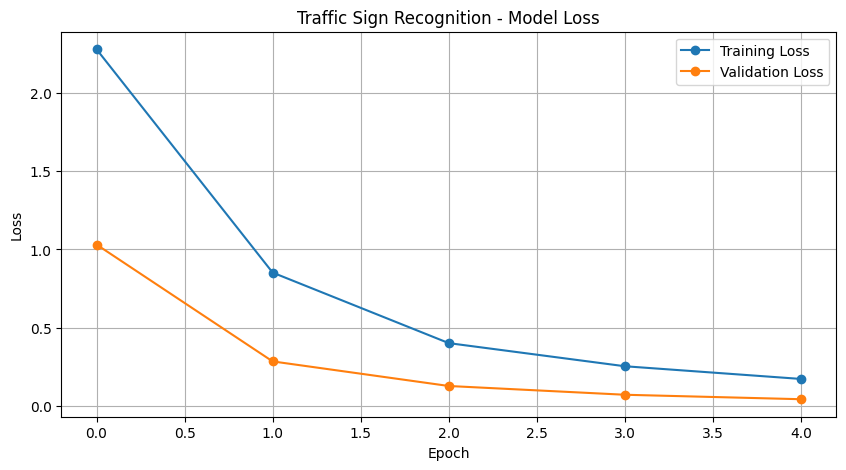

Both graphs saved successfully!


In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(history.history["accuracy"], marker="o", label="Training Accuracy")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation Accuracy")
plt.title("Traffic Sign Recognition - Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.savefig("/content/traffic_sign_accuracy.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(history.history["loss"], marker="o", label="Training Loss")
plt.plot(history.history["val_loss"], marker="o", label="Validation Loss")
plt.title("Traffic Sign Recognition - Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.savefig("/content/traffic_sign_loss.png", dpi=300, bbox_inches="tight")
plt.show()

print("Both graphs saved successfully!")

In [26]:
import shutil
import os

drive_folder = "/content/drive/MyDrive"

shutil.copy(
    "/content/traffic_sign_accuracy.png",
    os.path.join(drive_folder, "traffic_sign_accuracy.png")
)

shutil.copy(
    "/content/traffic_sign_loss.png",
    os.path.join(drive_folder, "traffic_sign_loss.png")
)

print("Both graphs copied to Google Drive!")

Both graphs copied to Google Drive!


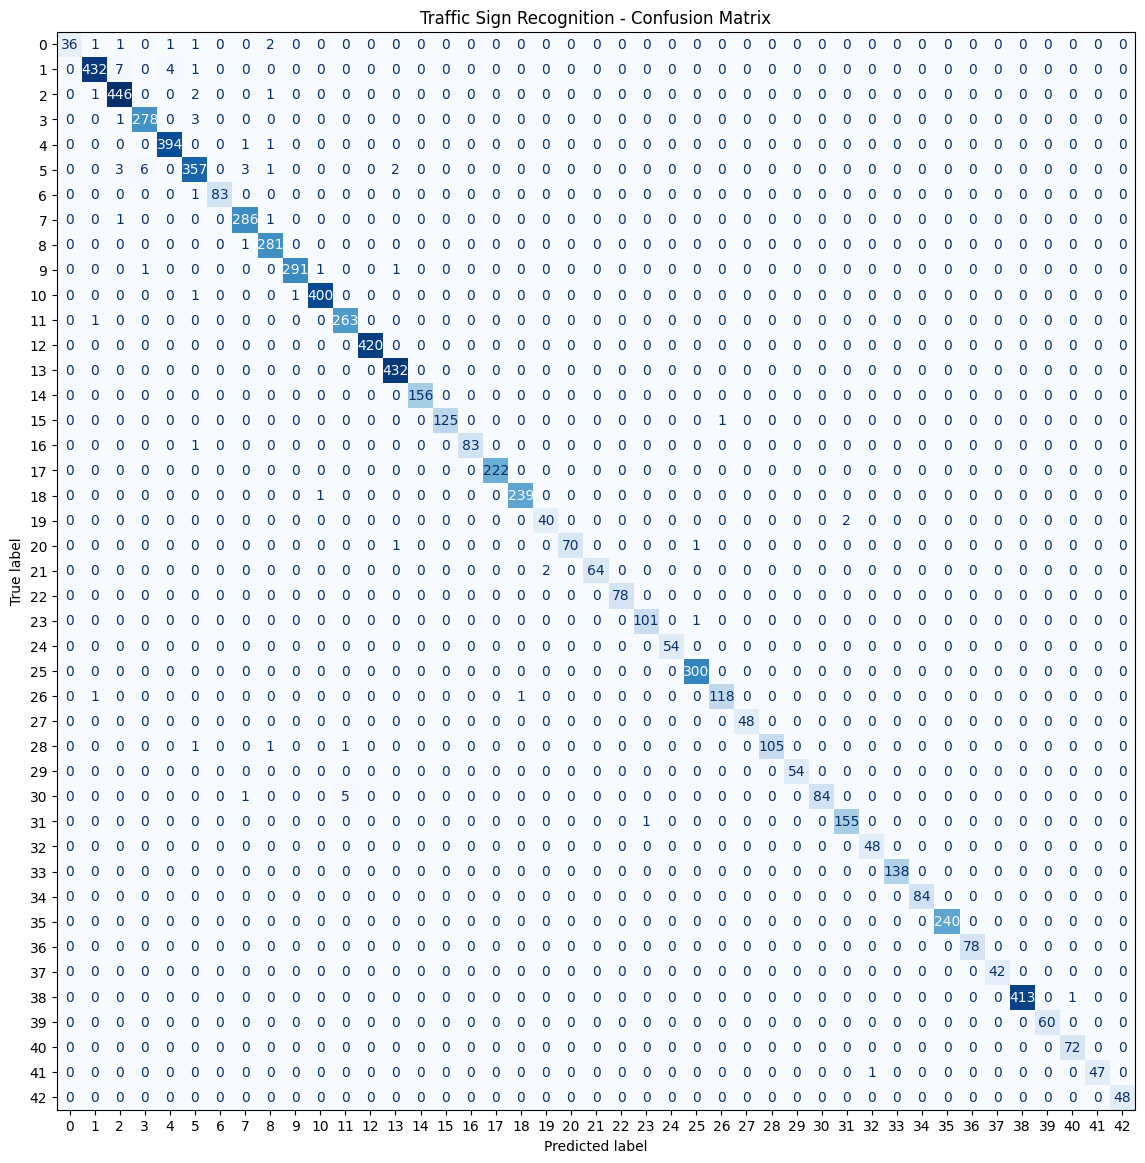

In [27]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

cm = confusion_matrix(y_val, y_pred)

fig, ax = plt.subplots(figsize=(14, 14))
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")

plt.title("Traffic Sign Recognition - Confusion Matrix")
plt.savefig(
    "/content/traffic_sign_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

In [28]:
import shutil

shutil.copy(
    "/content/traffic_sign_confusion_matrix.png",
    "/content/drive/MyDrive/traffic_sign_confusion_matrix.png"
)

print("Confusion matrix saved to Google Drive!")

Confusion matrix saved to Google Drive!


In [29]:
import os

folder = "/content/drive/MyDrive"

files = [
    "traffic_sign_cnn.keras",
    "traffic_sign_accuracy.png",
    "traffic_sign_loss.png",
    "traffic_sign_confusion_matrix.png"
]

for file in files:
    path = os.path.join(folder, file)
    print(("✅ " if os.path.exists(path) else "❌ ") + file)

✅ traffic_sign_cnn.keras
✅ traffic_sign_accuracy.png
✅ traffic_sign_loss.png
✅ traffic_sign_confusion_matrix.png
